In [1]:
import pandas as pd 

tweets =pd.read_csv('tweets.csv',encoding='UTF-8')

tweets.head()

,tweet
0,احد خيارات التنزهة بمدينة الرياض حديقة الحيوان...
1,حديقة جميلة للاطفال وسعر دخول ممتاز واكشاك بس...
2,ممتاز جدا عندي بس بعض الملاحظات والاقتراحات\n١...
3,حديقة منظمة وبها عديد كبير من الحيوانات\nالخدم...
4,فيه تجديدات حلوة ومكان جميل وسعر مناسب، نتمنى ...


In [2]:
positive = pd.read_csv('positive.csv',encoding='UTF-8')

positive.head()

,score,word
0,3,ممتاز
1,3,رائع
2,3,مبهر
3,3,جميل
4,3,ساحر


In [3]:
negative = pd.read_csv('negative.csv' ,encoding = "utf-8")

negative.tail()

,score,word
1114,-2,صعب
1115,-3,الخيبه
1116,-1,فاحش
1117,-2,زائد
1118,-3,مخيسة


In [4]:
pip install nltk

Note: you may need to restart the kernel to use updated packages.


In [5]:
pip install snowballstemmer

Note: you may need to restart the kernel to use updated packages.


In [6]:
import nltk 
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from snowballstemmer import stemmer

from snowballstemmer import stemmer

import string 


def remove_chars(text, del_chars):
    for char in del_chars:
        text = text.replace(char, "")
    return text



def cleaningText(text):
    numbers="0123456789"
    arabic_punctuation='''`÷×؛<>_()*^ـ،/:"؟.,'~¦+|!”…“–ـ'''
    english_punctuation=string.punctuation

    del_chars =english_punctuation+arabic_punctuation
    text = remove_chars(text,del_chars)

    text = text.replace('\n', ' ')  
       
    text = text.strip(' ')  
    return text

def filteringText(tokens_list):  
    
    listStopwords = stopwords.words('arabic')
    filtered = []
    for txt in tokens_list:
        if txt not in listStopwords:
            filtered.append(txt)
    return filtered


def toSentence(words_list):  
    sentence = ' '.join(word for word in words_list)
    return sentence

 
def stemmingText(tokens_list): 
    
    ar_stemmer = stemmer("arabic")
    tokens_list_stem = [ar_stemmer.stemWord(word) for word in tokens_list]
    return tokens_list_stem
    

In [7]:
ar_stemmer = stemmer("arabic")

stem = ar_stemmer.stemWord("رايع")
print (stem)

stem = ar_stemmer.stemWord("رائع")
print (stem)

stem = ar_stemmer.stemWord("رائعون")
print (stem)

stem = ar_stemmer.stemWord("رائعين")
print (stem)

رايع
رايع
رايع
رايع


In [8]:
nltk.download('punkt_tab')
text= "!أنا أحب الذهاب إلى الحديقة، كل يوم 9 صباحاً مع رفاقي هؤلاء "
print(text)

text=cleaningText(text)
print(text)

tokens_list=word_tokenize(text)
print(tokens_list)

tokens_list=filteringText(tokens_list)
print(tokens_list)

tokens_list=stemmingText(tokens_list)
print(tokens_list)

!أنا أحب الذهاب إلى الحديقة، كل يوم 9 صباحاً مع رفاقي هؤلاء 
أنا أحب الذهاب إلى الحديقة كل يوم 9 صباحاً مع رفاقي هؤلاء
['أنا', 'أحب', 'الذهاب', 'إلى', 'الحديقة', 'كل', 'يوم', '9', 'صباحاً', 'مع', 'رفاقي', 'هؤلاء']
['أحب', 'الذهاب', 'الحديقة', 'يوم', '9', 'صباحاً', 'رفاقي']
['احب', 'ذهاب', 'حديق', 'يوم', '9', 'صباح', 'رفاق']


[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [9]:
def text_preprocessing(text):
    text = cleaningText(text)
    tokens = word_tokenize(text)
    tokens = filteringText(tokens)
    tokens = stemmingText(tokens)
    return tokens

In [10]:
tweets['tweet_preprocessed'] = tweets['tweet'].apply(text_preprocessing)

tweets.drop_duplicates(subset = 'tweet_preprocessed', inplace = True)

In [11]:
positive['word_preprocessed'] = positive['word'].apply(text_preprocessing)
positive['word_preprocessed'] = positive['word_preprocessed'].apply(toSentence)

#  dropna  delete the Nan value
positive.drop_duplicates(subset = 'word_preprocessed', inplace = True)

positive.dropna(subset = 'word_preprocessed', inplace = True)

In [12]:
negative['word_preprocessed'] = negative['word'].apply(text_preprocessing)
negative['word_preprocessed'] = negative['word'].apply(toSentence)

negative.drop_duplicates(subset = 'word_preprocessed', inplace=True)

negative.dropna(subset='word_preprocessed',inplace=True)


In [13]:
dict_positive = dict()

for _, row in positive.iterrows():
    word=row['word_preprocessed'].strip()
    dict_positive[word] = int(row['score'])

dict_negative = dict()

for _, row in negative.iterrows():
    word=row['word_preprocessed'].strip()
    dict_negative[word] = int(row['score'])

In [14]:
def get_polarity(words_list):
    score = 0
    for word in words_list:
        if (word in dict_positive):
            score = score + dict_positive[word]
    for word in words_list:
        if (word in dict_negative):
            score = score + dict_negative[word]
            #  polarity  قطبية  النقاط  score 
    polarity=''
    if (score > 0):
        polarity = 'positive'
    elif (score < 0):
        polarity = 'negative'
    else:
        polarity = 'neutral'
    return score, polarity

In [15]:
for idx, row in tweets.iterrows():
    
    tweets_words=tweets.loc[idx,'tweet_preprocessed']
    
    score, polarity = get_polarity(tweets_words)
    tweets.loc[idx,'polarity_score'] =score
    tweets.loc[idx,'polarity'] =polarity

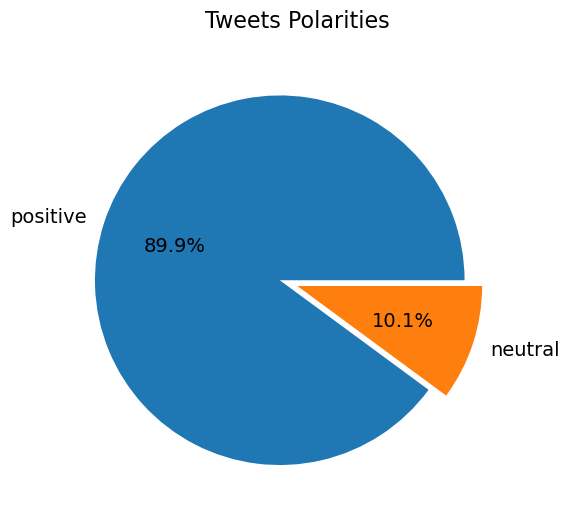

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 6))

x = tweets['polarity'].value_counts()
labels = x.index

# إنشاء explode ديناميكياً بحيث يفصل الشريحة الأولى فقط مهما كان عدد التصنيفات
explode = [0.1] + [0] * (len(x) - 1)

ax.pie(x=x, labels=labels, autopct='%1.1f%%', 
       explode=explode, textprops={'fontsize': 14})

ax.set_title('Tweets Polarities', fontsize=16, pad=20)
plt.show()

In [17]:
positive_tweets = tweets[tweets['polarity'] == 'positive']

positive_tweets = positive_tweets.sort_values(by = 'polarity_score', ascending=False)
positive_tweets[['tweet','polarity_score']].head()

,tweet,polarity_score
14642,"قصر جميل لكن مهمل من الدولة\nحكاية قصر ""الخواج...",140.0
15124,"""متحف حائل"".. سياحة مشوقة عبر الزمن في ""شتاء ا...",135.0
16223,والله رهيبة بشكل مو طبيعي وحلوة جداً في الشتاء...,119.0
14613,عرف الموقع التاريخي بـداية بـ قصر جبره والذي ي...,112.0
10291,معرض جميل ورائع انصح الجميع بزيارته 👍🏼\nكمية ا...,108.0


In [18]:
negitive_tweets = tweets[tweets['polarity'] == 'negitive']

negitive_tweets = negitive_tweets.sort_values(by = 'polarity_score', ascending=False)
negitive_tweets[['tweet','polarity_score']].head()

,tweet,polarity_score


In [19]:
!pip install wordcloud

In [20]:
!pip install arabic_reshaper

In [21]:
!pip install arabic_reshaper

In [22]:
!pip install python-bidi

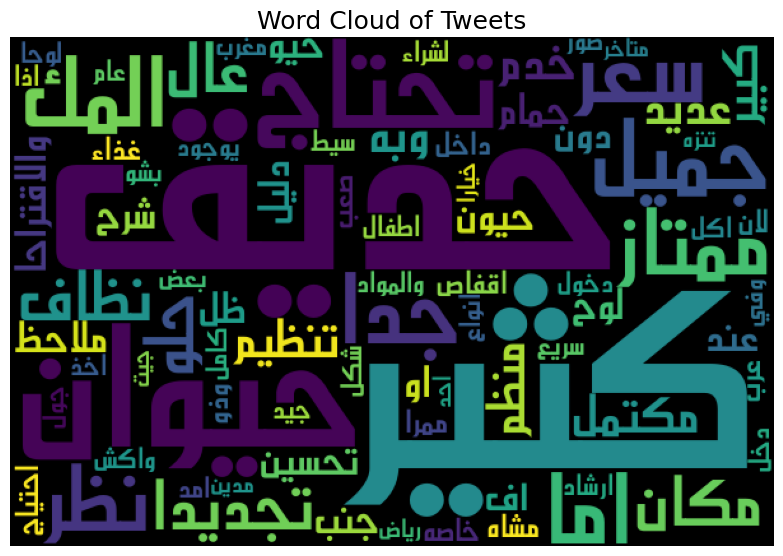

In [23]:
from wordcloud import WordCloud

import arabic_reshaper
from bidi.algorithm import get_display

list_words=''
i=0

for tweet in tweets['tweet_preprocessed']:
    for word in tweet:
        i=i+1
        if i>100:
            break
        list_words += ' '+(word)

reshaped_text = arabic_reshaper.reshape(list_words)
artext = get_display(reshaped_text)

wordcloud = WordCloud(font_path='DroidSansMono.ttf', 
                      width = 600, height = 400, 
                      background_color = 'black', 
                      min_font_size = 10).generate(artext)
fig, ax = plt.subplots(figsize = (8, 6))

ax.set_title('Word Cloud of Tweets', fontsize = 18)
ax.grid(False)
ax.imshow((wordcloud))
fig.tight_layout(pad=0)
ax.axis('off')
plt.show()

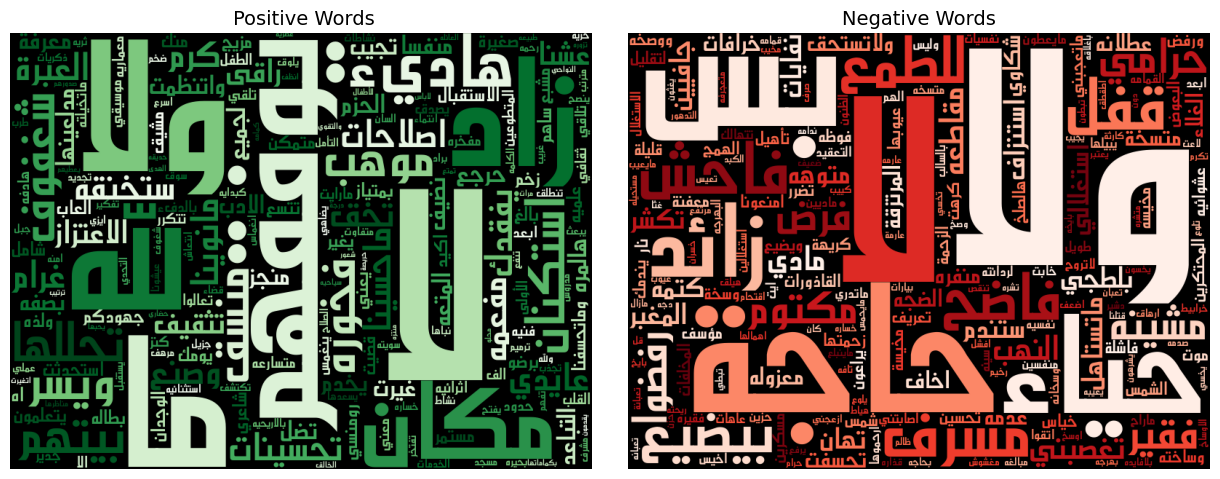

In [24]:
fig, ax = plt.subplots(1, 2,figsize = (12, 10))

positive_words=positive['word']

negative_words=negative['word']

list_words_positive=''

for word in positive_words.values:
    list_words_positive += ' '+(word)
reshaped_text = arabic_reshaper.reshape(list_words_positive)
artext = get_display(reshaped_text)

wordcloud_positive = WordCloud(font_path='DroidSansMono.ttf',
                               width = 800, height = 600, 
                               background_color = 'black', 
                               colormap = 'Greens',
                               min_font_size = 10).generate(artext)
ax[0].set_title(' Positive Words', fontsize = 14)
ax[0].grid(False)
ax[0].imshow((wordcloud_positive))
fig.tight_layout(pad=0)
ax[0].axis('off')

list_words_negative=''
for word in negative_words.values:
    list_words_negative += ' '+(word)
reshaped_text = arabic_reshaper.reshape(list_words_negative)
artext = get_display(reshaped_text)

wordcloud_negative = WordCloud(font_path='DroidSansMono.ttf',
                               width = 800, height = 600, 
                               background_color = 'black', colormap = 'Reds',
                               min_font_size = 10).generate(artext)
ax[1].set_title('Negative Words', fontsize = 14)
ax[1].grid(False)
ax[1].imshow((wordcloud_negative))
fig.tight_layout(pad=0)
ax[1].axis('off')

plt.show()

In [25]:
tweets.head()

,tweet,tweet_preprocessed,polarity_score,polarity
0,احد خيارات التنزهة بمدينة الرياض حديقة الحيوان...,"[احد, خيارا, تنزه, مدين, رياض, حديق, حيوان, جي...",10.0,positive
1,حديقة جميلة للاطفال وسعر دخول ممتاز واكشاك بس...,"[حديق, جميل, اطفال, سعر, دخول, ممتاز, واكش, سي...",18.0,positive
2,ممتاز جدا عندي بس بعض الملاحظات والاقتراحات\n١...,"[ممتاز, جدا, عند, ملاحظ, والاقتراحا, 1ف, كثير,...",7.0,positive
3,حديقة منظمة وبها عديد كبير من الحيوانات\nالخدم...,"[حديق, منظم, وبه, عديد, كبير, حيوان, خدم, مكتم...",11.0,positive
4,فيه تجديدات حلوة ومكان جميل وسعر مناسب، نتمنى ...,"[تجديدا, حلو, مكان, جميل, سعر, مناسب, نتمني, ي...",14.0,positive


In [26]:
from tensorflow.keras.preprocessing.text import Tokenizer


sentences = ['Artificial Intelligence Learning', 
                'Human Intelligence', 
                "Machine Learning", 
                "Deep Learning"]



tokenizer = Tokenizer(num_words=10)

tokenizer.fit_on_texts(sentences)

print(tokenizer.word_index)

{'learning': 1, 'intelligence': 2, 'artificial': 3, 'human': 4, 'machine': 5, 'deep': 6}


In [27]:
sequences = tokenizer.texts_to_sequences(sentences)
print(sequences)

[[3, 2, 1], [4, 2], [5, 1], [6, 1]]


In [28]:
# توحيد اطوال القوائم تضيف اصفار الى القوائم الاصغر 
from tensorflow.keras.preprocessing.sequence import pad_sequences

pads = pad_sequences(sequences ,maxlen=3) # [3, 2, 1]

In [29]:
sentence = tweets['tweet_preprocessed'].apply(toSentence)
sentence


0        احد خيارا تنزه مدين رياض حديق حيوان جيت متاخر ...
1        حديق جميل اطفال سعر دخول ممتاز واكش سيط لشراء ...
2        ممتاز جدا عند ملاحظ والاقتراحا 1ف كثير اما جنب...
3        حديق منظم وبه عديد كبير حيوان خدم مكتمل تنظيم ...
4        تجديدا حلو مكان جميل سعر مناسب نتمني يسمح دخول...
                               ...                        
23533                                                مكتوم
23534                                                 مشين
23537                                                 فاضح
23539                                                 مسرف
23544                                                 فاحش
Name: tweet_preprocessed, Length: 19930, dtype: object

In [30]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_words = 5000

sequence_max_len = 50

tokenizer = Tokenizer(num_words=max_words)

tokenizer.fit_on_texts(sentence.values)

seq =tokenizer.texts_to_sequences(sentence.values)

X= pad_sequences(seq)

In [31]:
print(sentence.values[35])
print(X[25])

رايع جدا تنظيم مميز اسعار رمز 👍🏻👍🏻 تجرب رايع اطفال استحق تجرب انصح زيار شتاء صيف تكون اجواء ساخن لاتطاق
[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  

In [32]:
polarity_encode = {'negative' : 0, 'neutral' : 1, 'positive' : 2}

y = tweets['polarity'].map(polarity_encode).values

In [33]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,random_state= 0, stratify=y)

In [34]:
import numpy as np

posCount = np.count_nonzero(y_train==2)
neuCount = np.count_nonzero(y_train==1)
negCount = np.count_nonzero(y_train==0)
print(negCount,  neuCount, posCount)     

total_3 = (posCount+ negCount+  neuCount) / 3

weight_for_0 = total_3 / negCount 
weight_for_1 = total_3 / neuCount 
weight_for_2 = total_3 / posCount 
print(weight_for_0, weight_for_1, weight_for_2)

class_weight = {0: weight_for_0, 1: weight_for_1, 2:weight_for_2}

0 1510 13437
inf 3.299558498896247 0.37079209148867553


C:\Users\user\AppData\Local\Temp\ipykernel_32052\1288254786.py:10: RuntimeWarning: divide by zero encountered in scalar divide
  weight_for_0 = total_3 / negCount


In [35]:
from keras.models import Sequential

from keras.layers import Input, Embedding, Dense, LSTM

from keras.optimizers import Adam

embed_dim = 32
hidden_unit = 16
dropout_rate = 0.2
learning_rate = 0.001

model = Sequential()

model.add(Input(shape=(sequence_max_len,)))

model.add(Embedding(input_dim = max_words, output_dim = embed_dim))

model.add(LSTM(units = hidden_unit ,dropout=dropout_rate))

model.add(Dense(units = 3, activation = 'softmax'))

In [42]:
model.compile(
    optimizer='adam', # or your chosen optimizer
    loss='sparse_categorical_crossentropy', # or your loss function
    metrics=['accuracy'] # <--- ADD THIS
)

In [43]:
epochs =10
batch_size = 128
history = model.fit(X_train,y_train, class_weight=class_weight, 
                    epochs = epochs, batch_size=batch_size,
                    validation_data =(X_test,y_test))

Epoch 1/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 17s 126ms/step - accuracy: 0.7844 - loss: 0.3710 - val_accuracy: 0.9039 - val_loss: 0.2631
Epoch 2/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 13s 115ms/step - accuracy: 0.9296 - loss: 0.1168 - val_accuracy: 0.9625 - val_loss: 0.1019
Epoch 3/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 17s 142ms/step - accuracy: 0.9741 - loss: 0.0419 - val_accuracy: 0.9735 - val_loss: 0.0764
Epoch 4/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 17s 144ms/step - accuracy: 0.9859 - loss: 0.0234 - val_accuracy: 0.9801 - val_loss: 0.0548
Epoch 5/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 17s 145ms/step - accuracy: 0.9926 - loss: 0.0141 - val_accuracy: 0.9829 - val_loss: 0.0501
Epoch 6/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 16s 133ms/step - accuracy: 0.9951 - loss: 0.0098 - val_accuracy: 0.9845 - val_loss: 0.0495
Epoch 7/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 17s 146ms/step - accuracy: 0.9967 - loss: 0.0069 - val_accuracy: 0.9849 - val_loss: 0.0497
Epoch 8/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 18s 153ms/step - accuracy: 0.9979 - loss: 0

In [44]:
history.history

{'accuracy': [0.7843714356422424,
  0.9295510649681091,
  0.9741085171699524,
  0.9858834743499756,
  0.9925737380981445,
  0.9951160550117493,
  0.9966548681259155,
  0.9978591203689575,
  0.9981266856193542,
  0.998862624168396],
 'loss': [0.3709888756275177,
  0.11677417904138565,
  0.04192211851477623,
  0.023406723514199257,
  0.014142341911792755,
  0.009750920347869396,
  0.006905392277985811,
  0.005362733732908964,
  0.00423237681388855,
  0.005335369147360325],
 'val_accuracy': [0.9038731455802917,
  0.9624723792076111,
  0.9735099077224731,
  0.9801324605941772,
  0.9829419851303101,
  0.9845474362373352,
  0.9849488139152527,
  0.9851495027542114,
  0.9851495027542114,
  0.9855508804321289],
 'val_loss': [0.2630794644355774,
  0.10187825560569763,
  0.07641500979661942,
  0.054774049669504166,
  0.050136130303144455,
  0.049492668360471725,
  0.04972737282514572,
  0.04990229383111,
  0.05081750825047493,
  0.05212262272834778]}

In [45]:
train_accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

print("Train Accuracy:", train_accuracy[-1])
print("Validation Accuracy:", val_accuracy[-1])

Train Accuracy: 0.998862624168396
Validation Accuracy: 0.9855508804321289


In [46]:
# create network to find the best  weights  التقيم المتقاطع 
def create_model(embed_dim = 32, 
                 hidden_unit = 16, 
                 dropout_rate = 0.2, 
                 learning_rate = 0.001):
    
    model = Sequential()
    
    model.add(Embedding(input_dim = max_words, output_dim = embed_dim, input_length = sequence_max_len))
    
    model.add(LSTM(units = hidden_unit ,dropout=dropout_rate))
    
    model.add(Dense(units = 3, activation = 'softmax'))
    
    model.compile(loss = 'sparse_categorical_crossentropy', 
                  optimizer = Adam(learning_rate = learning_rate), 
                  metrics = ['accuracy'])
    return model

In [47]:
pip install scikeras

Note: you may need to restart the kernel to use updated packages.


In [48]:
from scikeras.wrappers import KerasClassifier

model_keras = KerasClassifier(model = create_model, epochs = 25, batch_size=128)

In [49]:
param_grid = {
    'model__embed_dim': [32, 64],
    'model__hidden_unit': [16, 32, 64 ],
    'model__dropout_rate': [0.2, 0.5],
    'model__learning_rate': [0.01, 0.001, 0.0001]
}

In [50]:
'''
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(estimator = model_keras, param_grid = param_grid, cv = 5)
grid_result = grid.fit(X_train, y_train)

results_df = pd.DataFrame(grid_result.cv_results_)

results_df.to_csv('grid_search_results.csv', index=False)

print("Best parameters: ", grid_result.best_params_)

print("Best accuracy: ", grid_result.best_score_)
'''

'\nfrom sklearn.model_selection import GridSearchCV\n\ngrid = GridSearchCV(estimator = model_keras, param_grid = param_grid, cv = 5)\ngrid_result = grid.fit(X_train, y_train)\n\nresults_df = pd.DataFrame(grid_result.cv_results_)\n\nresults_df.to_csv(\'grid_search_results.csv\', index=False)\n\nprint("Best parameters: ", grid_result.best_params_)\n\nprint("Best accuracy: ", grid_result.best_score_)\n'

In [51]:
model = create_model(embed_dim = 64, 
                        hidden_unit = 64, 
                        dropout_rate = 0.2, 
                        learning_rate = 0.001)


history = model.fit(X_train, y_train, class_weight=class_weight,
                             epochs=epochs, batch_size=batch_size,
                             validation_data=(X_test, y_test))

Epoch 1/10


C:\ProgramData\anaconda3\Lib\site-packages\keras\src\layers\core\embedding.py:103: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


117/117 ━━━━━━━━━━━━━━━━━━━━ 83s 691ms/step - accuracy: 0.7850 - loss: 0.2571 - val_accuracy: 0.9270 - val_loss: 0.1769
Epoch 2/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 84s 716ms/step - accuracy: 0.9576 - loss: 0.0546 - val_accuracy: 0.9729 - val_loss: 0.0764
Epoch 3/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 77s 655ms/step - accuracy: 0.9877 - loss: 0.0178 - val_accuracy: 0.9829 - val_loss: 0.0524
Epoch 4/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 84s 715ms/step - accuracy: 0.9922 - loss: 0.0118 - val_accuracy: 0.9823 - val_loss: 0.0468
Epoch 5/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 81s 690ms/step - accuracy: 0.9966 - loss: 0.0060 - val_accuracy: 0.9858 - val_loss: 0.0504
Epoch 6/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 76s 649ms/step - accuracy: 0.9982 - loss: 0.0038 - val_accuracy: 0.9872 - val_loss: 0.0496
Epoch 7/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 69s 587ms/step - accuracy: 0.9989 - loss: 0.0028 - val_accuracy: 0.9860 - val_loss: 0.0537
Epoch 8/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 89s 765ms/step - accuracy: 0.9991 - loss: 0.0023 - val

In [52]:
train_accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

print("Train Accuracy:", train_accuracy[-1])
print("Validation Accuracy:", val_accuracy[-1])

Train Accuracy: 0.999397873878479
Validation Accuracy: 0.9875577092170715


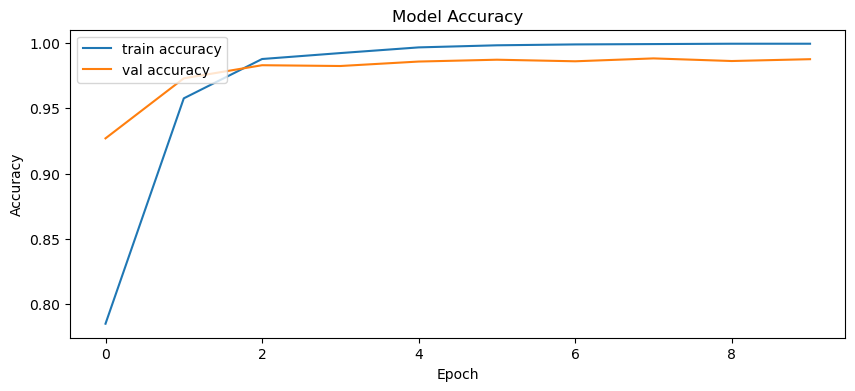

In [53]:
fig, ax = plt.subplots(figsize = (10, 4))
ax.plot(history.history['accuracy'], label = 'train accuracy')
ax.plot(history.history['val_accuracy'], label = 'val accuracy')
ax.set_title('Model Accuracy')
ax.set_xlabel('Epoch')
ax.set_ylabel('Accuracy')
ax.legend(loc = 'upper left')
plt.show()

In [60]:
model.save('sa_model.keras_2.keras')

In [61]:
import pickle

tokenizer_path = 'sa_tokenizer'
with open(tokenizer_path, 'wb') as file:
    pickle.dump(tokenizer, file)

In [62]:
from keras.models import load_model
import pickle

def classify_tweets(tweets, model_path, tokenizer_path, sequence_max_len):
    processed_tweets = []
    for x in tweets:
        
        y = text_preprocessing(x)

        y = toSentence(y)
        
        processed_tweets.append(y)

    model = load_model(model_path)
    
    with open(tokenizer_path, 'rb') as file:
        tokenizer = pickle.load(file)

    text_2_seq = tokenizer.texts_to_sequences(processed_tweets)

    text_pad = pad_sequences(text_2_seq, maxlen=sequence_max_len)

    predictions=model.predict(text_pad)

    sentiments = []
    for pred in predictions:
        max = np.argmax(pred, axis=0)
        if max == 0:
            sentiments.append("Negative")
        elif max == 1:
            sentiments.append("Neutral")
        else:
            sentiments.append("Positive")
    return sentiments

In [64]:
new_tweets=["مكان وسخ",
        "مكان رائع وجميل",
        "من أجمل الأماكن التي زرتها بحياتي",
        "يمكن التسوق فيها"]

predictions = classify_tweets(new_tweets,'sa_model.keras','sa_tokenizer',50)

for sentence, prediction in zip(new_tweets, predictions):
    print(f"Sentence: {sentence} - Sentiment: {prediction}  ")

C:\ProgramData\anaconda3\Lib\site-packages\keras\src\layers\core\embedding.py:103: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


TypeError: <class 'keras.src.models.sequential.Sequential'> could not be deserialized properly. Please ensure that components that are Python object instances (layers, models, etc.) returned by `get_config()` are explicitly deserialized in the model's `from_config()` method.

config={'module': 'keras', 'class_name': 'Sequential', 'config': {'name': 'sequential_3', 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_input_shape': [None, 50], 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'embedding_3_input'}, 'registered_name': None}, {'module': 'keras.layers', 'class_name': 'Embedding', 'config': {'name': 'embedding_3', 'trainable': True, 'dtype': 'float32', 'batch_input_shape': [None, 50], 'input_dim': 5000, 'output_dim': 64, 'embeddings_initializer': {'module': 'keras.initializers', 'class_name': 'RandomUniform', 'config': {'minval': -0.05, 'maxval': 0.05, 'seed': None}, 'registered_name': None}, 'embeddings_regularizer': None, 'activity